# An O(3)-equivariant flow and learned quotient dynamics

Run the cells in order to restore the bundled evidence, load the saved checkpoint with `retrain=False`, and regenerate the figures. The environments and installation commands are in [the README](../README.md).

The setup cell imports these helpers from `src/`.

| Helper | Source | Produces |
| --- | --- | --- |
| `workspace` | `notebook_support.py` | Restored inputs, verified dependency checksums, plotting cache paths |
| `fit_quotient` | `quotient_fitting.py` | Saved fit directory and training/validation loss plot |
| `analytical_reference`, `show_analytical` | `example_plots.py` | Analytical replay and flow diagrams (`analytical_reference` is an import alias) |
| `show_quotient_fit` | `quotient_notebook.py` | Encoder, learned dynamics, reconstruction plots and held-out errors |
| `quotient_domain_study` | `quotient_domain_notebook.py` | Fixed-checkpoint CMGDB grid study, reusing matching saved results |


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "upstream.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
from notebook_support import workspace
ROOT, EXAMPLES, DATA = workspace()
from quotient_fitting import fit_quotient
from example_plots import paper_reference as analytical_reference, show_analytical
from quotient_notebook import show_quotient_fit
from quotient_domain_notebook import quotient_domain_study, show_domain_comparison
from o3_joint_comparison import show_joint_comparison

from o3_reconstruction import show_reconstruction


Pinned dependencies 21acca6 and numerical input checksums verified.


## Flow and physical quotient

Let $X=[-1.5,1.5]\times B^3_{1.5}$, where $B^3_{1.5}=\{v\in\mathbb R^3:\|v\|\le1.5\}$. For $(a,v)\in X$,
$$\dot a=a(1-a^2),\qquad \dot v=(1-2a^2-\|v\|^2)v.$$
The action is $(a,v)\mapsto(a,Qv)$ for $Q\in O(3)$, including reflections. The physical quotient is $q:X\to R=[-1.5,1.5]\times[0,1.5]$, $q(a,v)=(a,r)$ with $r=\|v\|$. For the flow $F_t:X\to X$, the quotient time-$\log3$ map $\bar F:R\to R$ is
$$\bar F(a,r)=\left(\frac{3a}{\sqrt d},\frac{3r}{\sqrt{d(d+8r^2)}}\right),\qquad d=1+8a^2.$$
The next cell displays the analytical quotient field. The origin is repelling, $(0,1)$ is a saddle, and $(\pm1,0)$ attract. The fiber above $(0,1)$ is an equilibrium sphere.


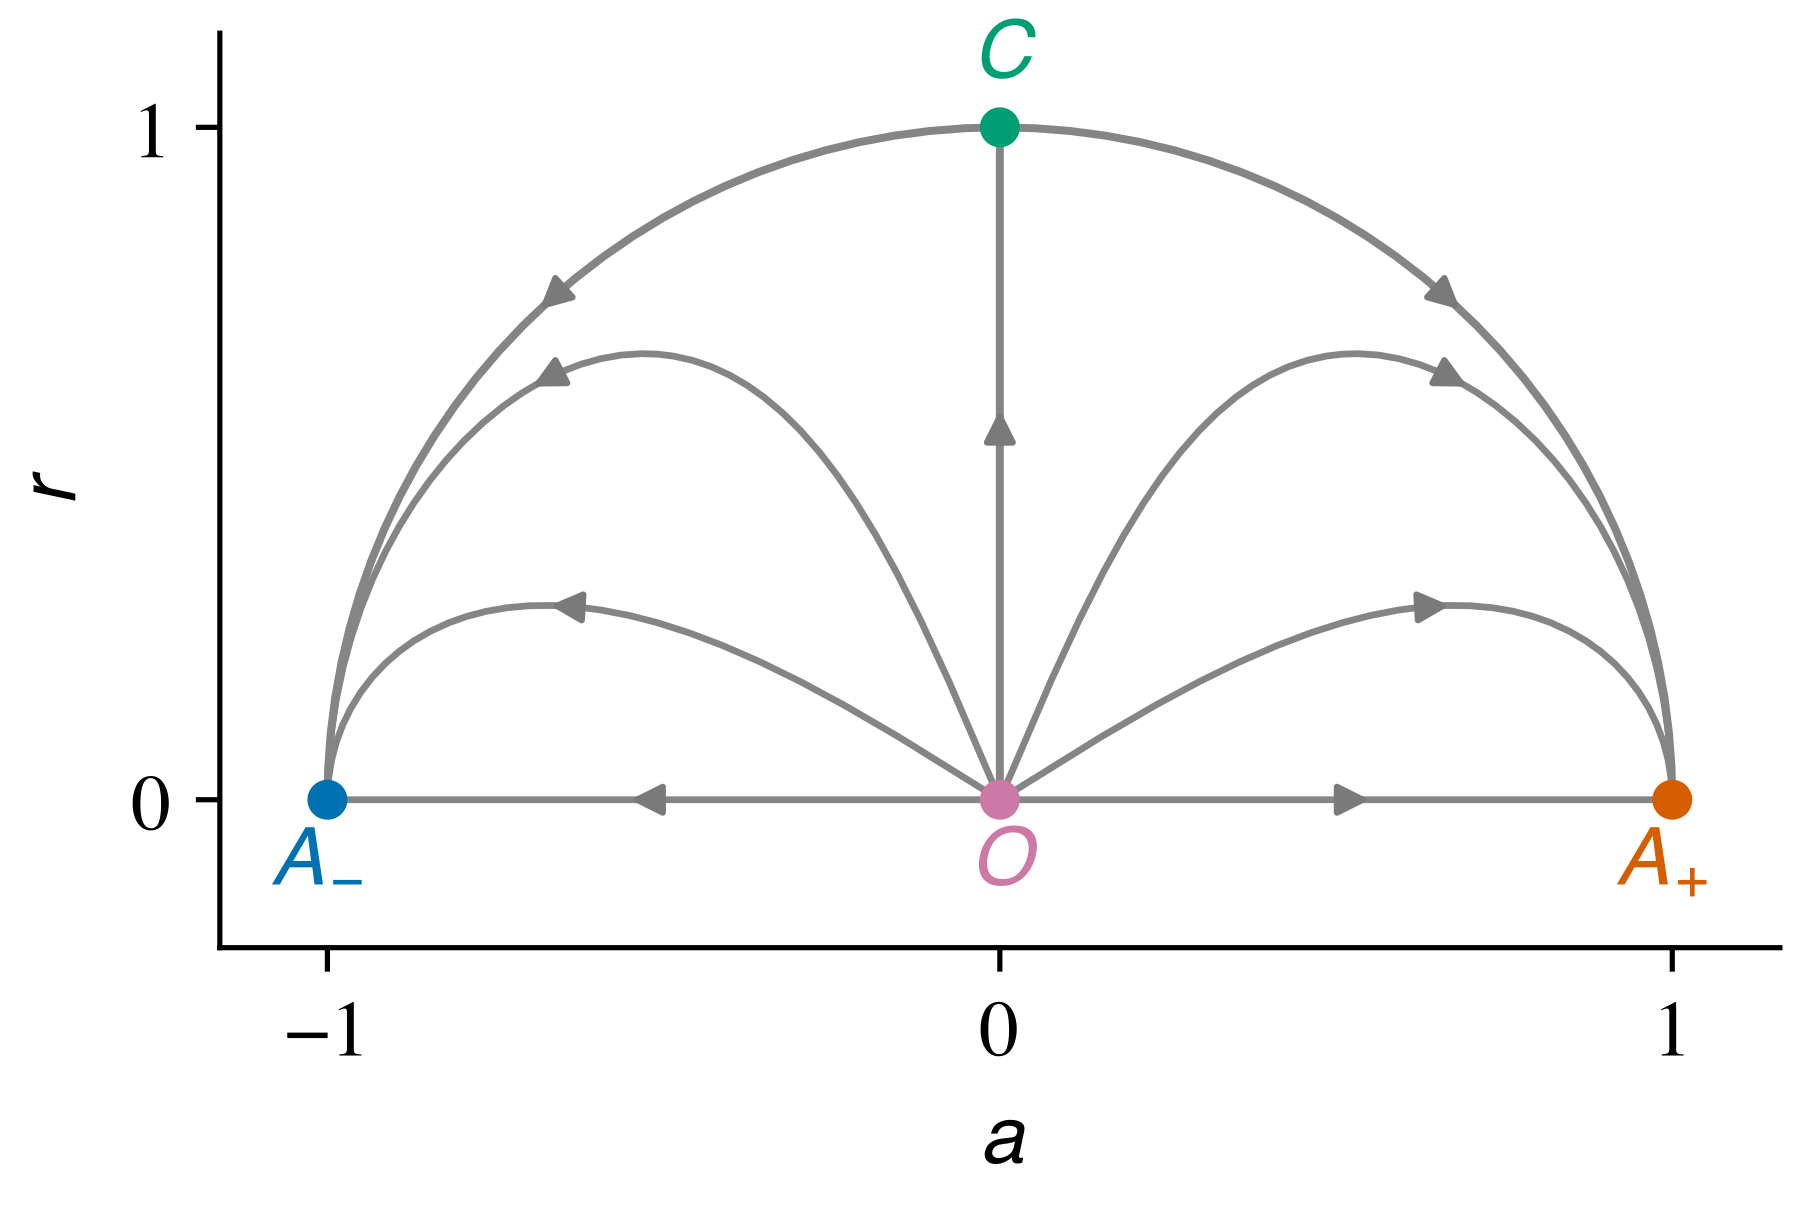

In [2]:
reference = analytical_reference(ROOT, EXAMPLES, DATA, "o3")
show_analytical(reference, "o3")

## Positive-gain encoder, map, and decoder

Let $H=\mathbb R\times[0,\infty)$. An invariant network $N_\theta:\mathbb R^4\to\mathbb R^2$ defines $E_\theta:X\to H$,
$$E_\theta(x)=q(x)\odot\exp(0.25\tanh N_\theta(S^{-1}x)).$$
The diagonal matrix $S$ contains the training-pair RMS scalar scale and a shared RMS vector-component scale. The encoder explicitly uses the known invariants $(a,\|v\|)$ and learns positive corrections.

For networks $N_\psi,N_\phi:H\to\mathbb R^2$, define gains $g_\psi,k_\phi:H\to(0,\infty)^2$, the learned map $f_\psi:H\to H$, and quotient decoder $\widehat q_\phi:H\to H$ by
$$g_\psi(\xi)=\exp(3\tanh(N_\psi(\xi)/3)),\qquad f_\psi(\xi)=\xi\odot g_\psi(\xi),$$
$$k_\phi(\xi)=\exp(0.5\tanh N_\phi(\xi)),\qquad\widehat q_\phi(\xi)=\xi\odot k_\phi(\xi).$$
Exponentials and products act componentwise. The representative decoder $D_\phi:H\to\mathbb R^4$ is $D_\phi(\xi)=(\widehat q_{\phi,1}(\xi),\widehat q_{\phi,2}(\xi),0,0)$. Its output need not lie in $X$. Positive gains preserve signs and coordinate axes, but do not ensure $f_\psi(E_\theta(X))\subseteq E_\theta(X)$.

For pairs $x^+=F_\tau(x)$, let $u$ range over both members of the training pairs. With state scale $s$ and latent dimension $m$, the implemented loss is

$$L=L_{\rm rec}+L_{\rm pred}+L_{\rm con}+0.1L_{\rm cyc}+0.01L_{\rm spread},$$
$$L_{\rm rec}=\mathbb E_u\frac{d_G(D(E(u)),u)^2}{s^2},\qquad
L_{\rm pred}=\mathbb E_x\frac{d_G(D(f(E(x))),x^+)^2}{s^2},$$
$$L_{\rm con}=\frac1m\mathbb E_x\|f(E(x))-E(x^+)\|^2,\qquad
L_{\rm cyc}=\frac1m\mathbb E_u\|E(D(E(u)))-E(u)\|^2,$$
$$L_{\rm spread}=\frac1m\sum_{j=1}^m\bigl(\operatorname{std}_u E_j(u)-0.5\bigr)^2.$$

Here $d_G:\mathbb R^n\times\mathbb R^n\to[0,\infty)$ is the minimum Euclidean distance over the stated orthogonal action. Cycle evaluation uses the encoder formula on the decoded representatives. The loss and optimizer are in `src/quotient_fitting.py`, and the network construction and reload functions are in `src/quotient_runtime.py`.

Here $n=4$, $m=2$, $s=1.5$, and $d_G((a,v),(\widehat a,\widehat v))^2=(a-\widehat a)^2+(\|v\|-\|\widehat v\|)^2$. The encoder formula extends to $\mathbb R^4$ for cycle evaluation. Latent coordinates are not standardized further.

All three EMLP/Objax networks have width 32 and two layers. Joint training uses batches of 256, 20,000 updates, and learning rate decaying from $10^{-3}$ to $2\cdot10^{-5}$. Training, validation, and test sets contain 16,384, 4,096, and 4,096 points. Scalar and radius are sampled uniformly on their intervals and directions uniformly on $S^2$. This is not uniform volume sampling in $X$. No special points are inserted. Validation loss selects the checkpoint before CMGDB.

The next cell loads the saved fit and loss curve. Both training and CMGDB use one step of duration $\tau=\log3$.


Loaded raw-state o3 quotient fit (seed 0).


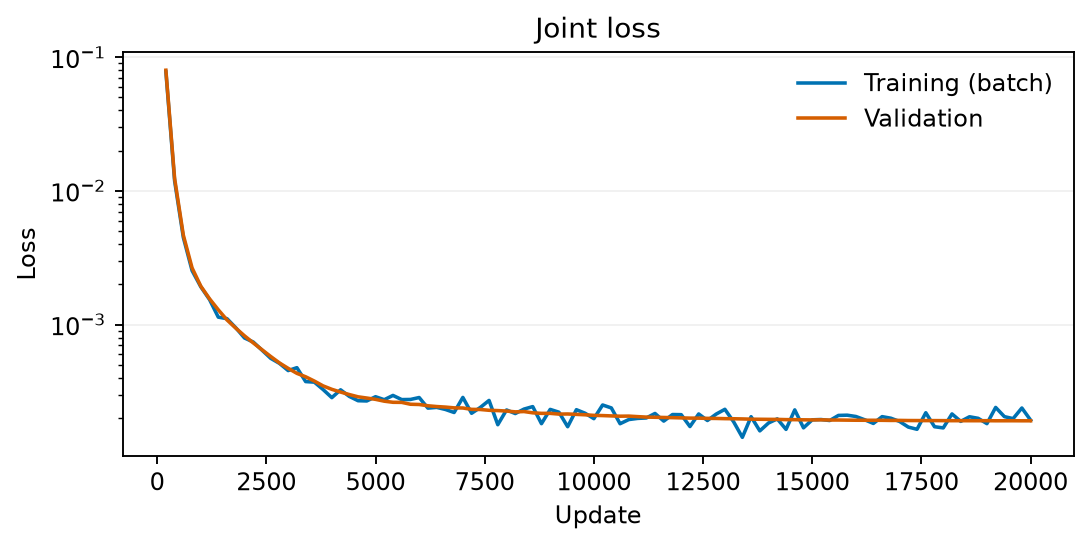

In [3]:
import numpy as np
fit = fit_quotient("o3", training="joint", parameterization="gain", seed=0,
                   train_starts=16384, validation_starts=4096, test_starts=4096,
                   joint_steps=20000, training_boundary_fraction=0.0,
                   validation_boundary_fraction=0.0, time_step=float(np.log(3)),
                   cmgdb_iterations=1, retrain=False, live=True)

The next cell displays the saved encoder, learned dynamics, orbit reconstruction, and held-out reconstruction, one-step, and ten-step errors.

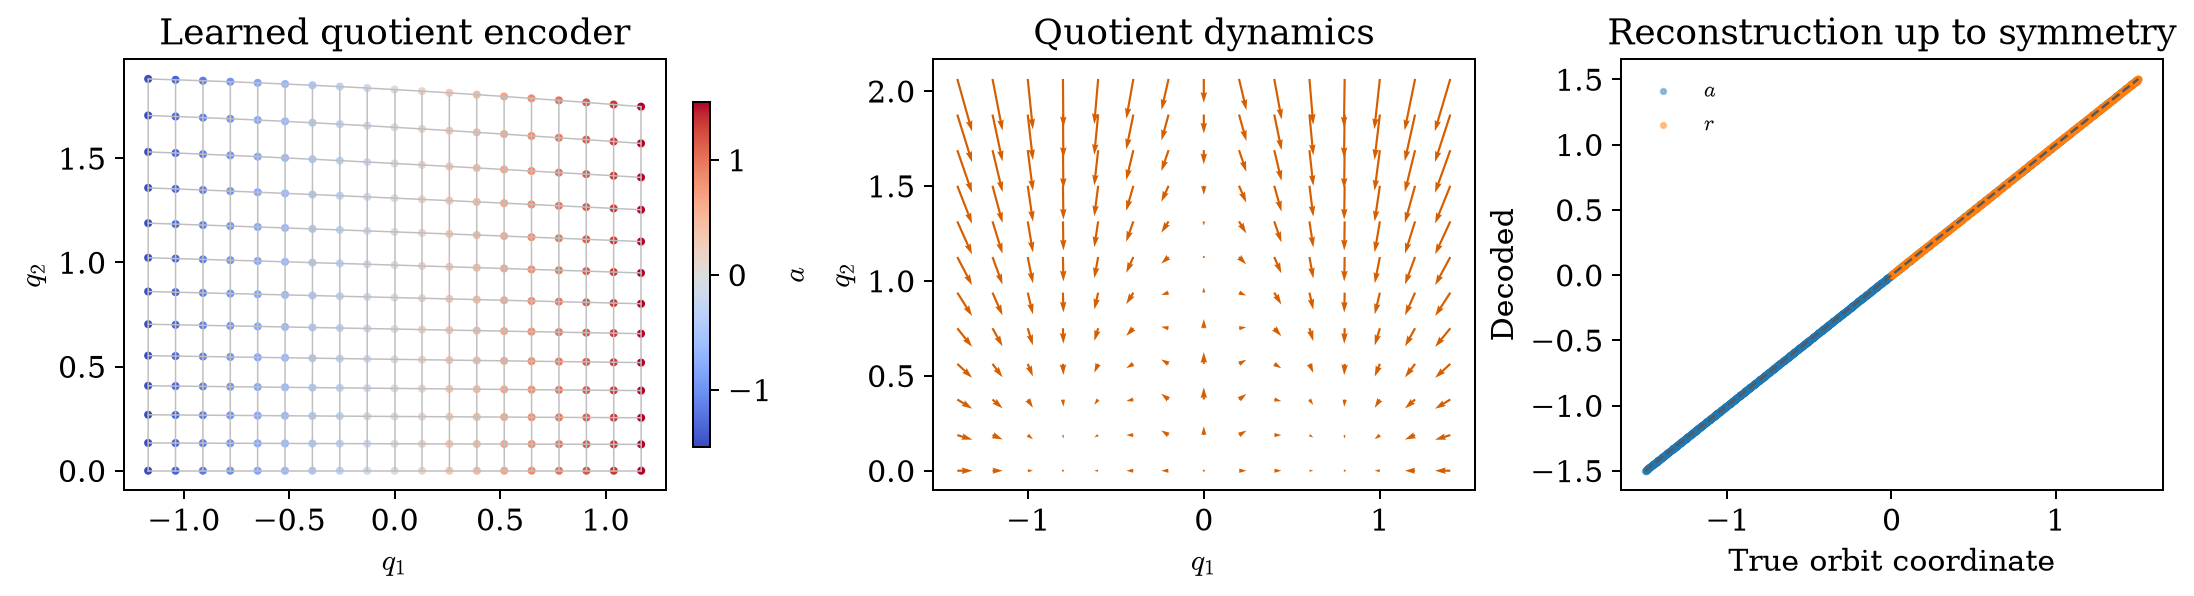

Held-out orbit RMS / state scale,Reconstruction,One step,Ten steps
Raw states,0.10%,0.38%,0.22%


In [4]:
show_quotient_fit(fit)

## CMGDB and the specified lift

The next cell loads levels 5–8. `show_joint_comparison` from `src/o3_joint_comparison.py` displays the analytical and learned graphs, aggregation checks, and domain diagnostics. `show_reconstruction` from `src/o3_reconstruction.py` displays local index reconstruction and sampled encoder defects.

Each rectangular cell uses a $5\times5$ sample grid. Image hulls are inflated by $10^{-9}$, with the radius lower bound clipped at zero. CMGDB computes native components and relative-chain indices over $\mathbb F_5$. Aggregation includes connecting cells and recomputes indices. The learned graphs have six native components and four aggregates on the $64^2$, $128^2$, and $256^2$ grids, with ordering $O\to C\to A_\pm$. Matched-time analytical graphs have 4, 5, and 4 native components. The displayed basin colors use a sampled $64^2$ one-step-image cell union in each model's coordinates. White cells are uncolored, not necessarily outside a basin.

Writing $g_\psi=(g_1,g_2)$, the specified lift $\widetilde F:\mathbb R^4\to\mathbb R^4$ is
$$\widetilde F(s,w)=(s g_1(s,\|w\|),g_2(s,\|w\|)w).$$
It preserves fiber direction. Saved Arb bounds verify local indices $H_4$ at the origin, $H_1,H_3$ at the saddle sphere, and $H_0$ at the sinks, with identity maps over $\mathbb F_5$. Sampled graphs and encoder checks do not establish an exact conjugacy to the physical ODE or uniform model-error bounds.


Grid per axis,Analytical time 1.099,Learned rectangle,Learned encoder image
32,4,8,8
64,4,6,6
128,5,6,6
256,4,6,6


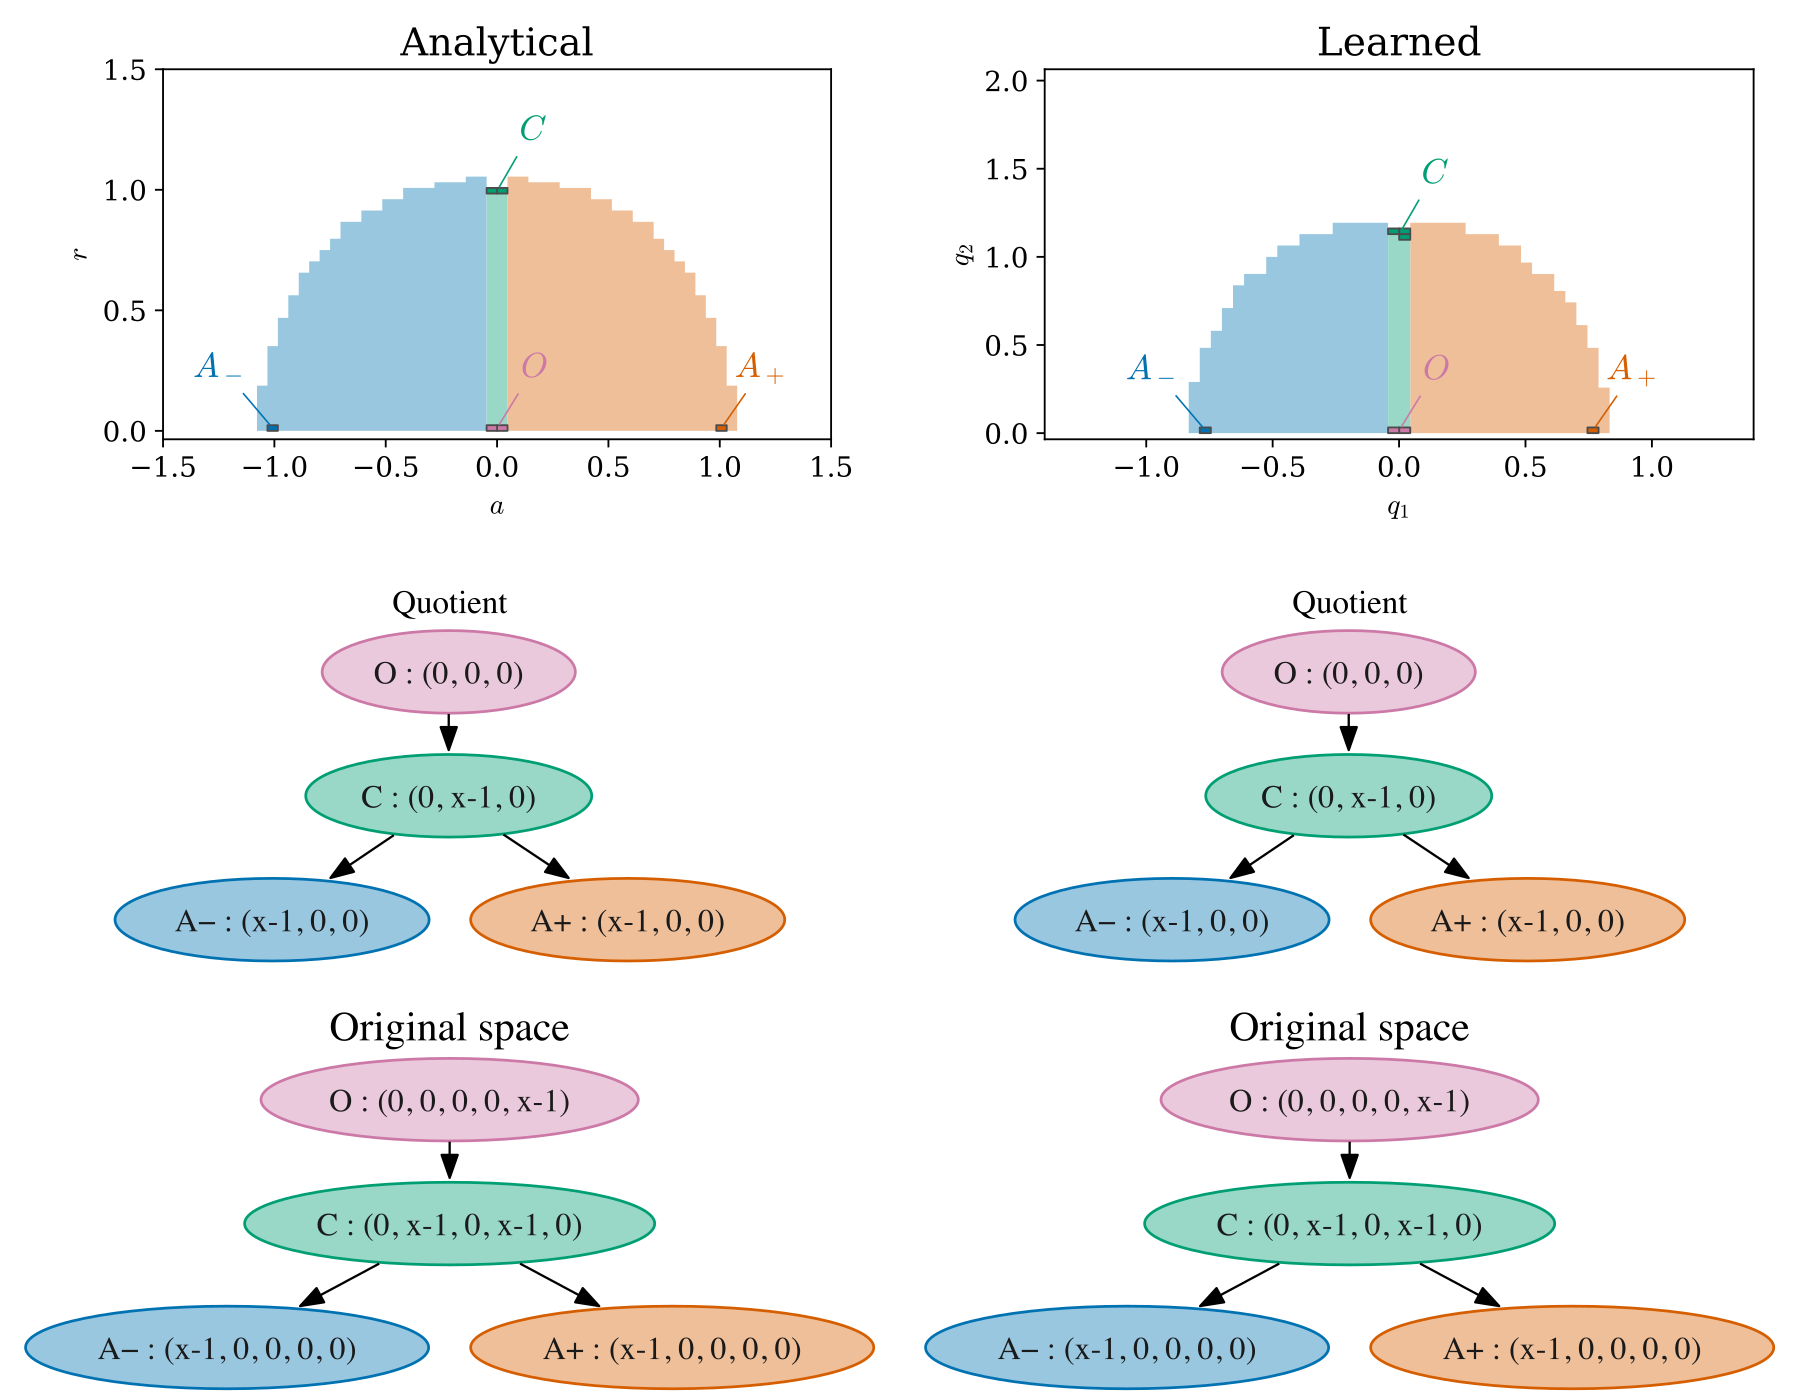

Labels and colors identify the four aggregates. The middle row shows the corresponding computed quotient indices on the rectangular grids; these indices are not transferred to the restricted Atlas domain. The bottom row reconstructs the original-space indices using degree +1 sphere fibers (the specified learned lift in the right column). Solid cells are native Morse sets, colored by their aggregate. At **64 × 64**, pale basin colors are restricted to the one-step image cells; pale green marks O-to-C paths. Each panel uses its own quotient coordinates. White is uncolored, not necessarily outside the basin. These are finite-graph labels, not certified RoA. Index computations use the finer grids reported below.

Grid,Native learned,Aggregated,Analytical graph + indices
64,6,4,Match
128,6,4,Match
256,6,4,Match


Grid,Aligned grid: native nodes,Half-cell shift: native nodes,All aggregated indices match
128,4,7,Yes
256,4,7,Yes


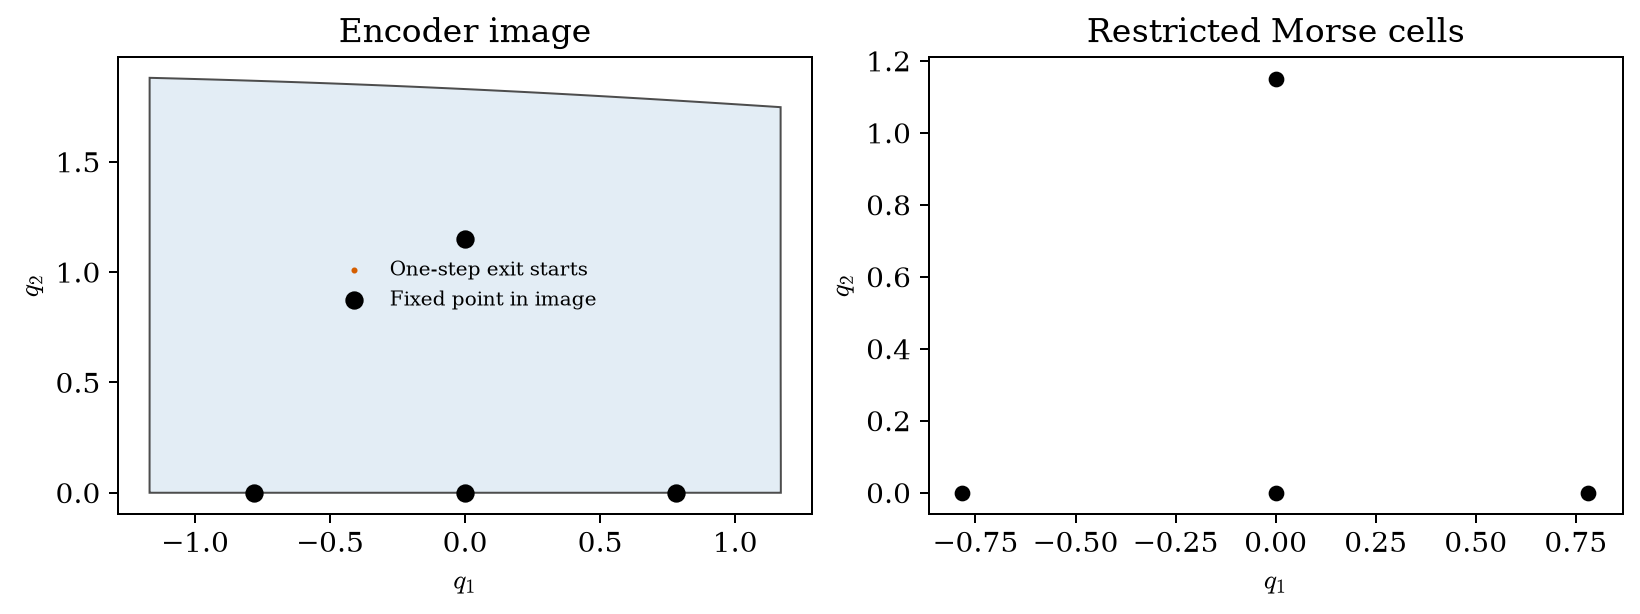

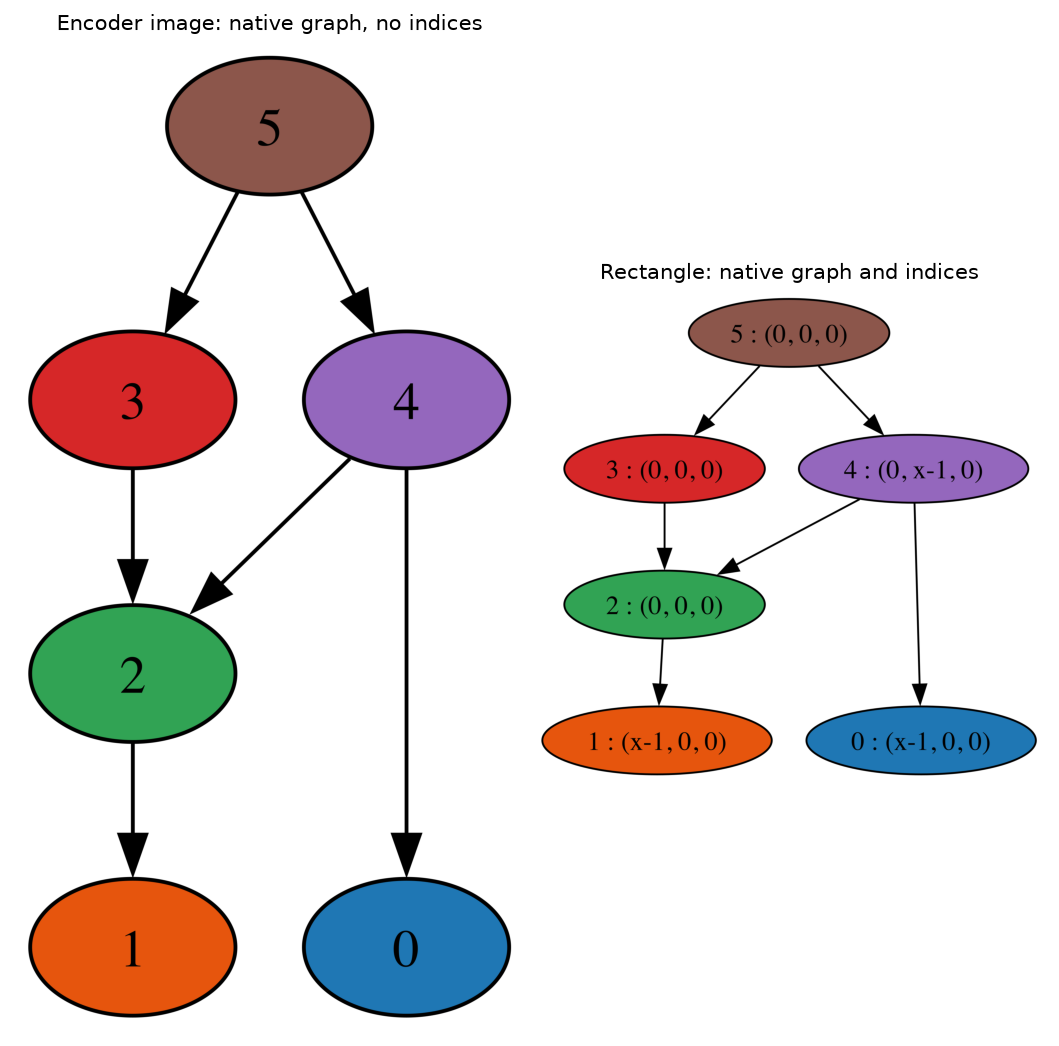

### Original-space reconstruction

The nonzero-radius fibers are $S^2$ and collapse on $P=\{r=0\}$. For the specified direction-preserving lift, let $(B,L)$ be a quotient index pair, with isolating neighborhood $B$ and exit set $L$. Its lifted pair is $(N_X,L_X)$. With coefficients in $\mathbb F_5$,

$$H_k(N_X,L_X) \cong H_k(B,L)\oplus H_{k-2}(B,L\cup(B\cap P)).$$

Arb interval bounds verify local expansion/contraction and unique fixed-point brackets for this saved map. These give a local isolating continuation to the positive normal forms, whose index maps are identities. CMGDB computes the relative-chain indices over $\mathbb F_5$; entries below run from degree 0 to 4.


Set,Quotient classes,Additional original-space classes,Original-space classes
Origin,None,H₄,H₄
Saddle sphere,H₁,H₃,"H₁, H₃"
Each sink,H₀,None,H₀


The quotient graph alone does not determine the fiber degree. The specified lift has degree +1. Local bounds are restored to `build/o3-certification/local-index-argument.md`.

**Approximate dynamics agreement:** at physical quotient fixed points, the largest one-step defect $\|f(E(x_*))-E(x_*)\|$ is **0.0039923** (sample interval 1.0986). The learned lifts’ verified local indices match the analytical indices. Transfer to the physical ODE requires suitable encoder coordinates and a neighborhood-wide error bound small enough to preserve isolation along a continuation; the sampled residual does not establish these conditions. The restored `build/conjugacy-check/claim-scope.md` gives the check details.

In [5]:
study = quotient_domain_study(fit, levels=(5, 6, 7, 8))
show_joint_comparison(reference, fit, study)
reconstruction = show_reconstruction(fit)
